# the wavelength span is too broad compared to the level 2 stuff

In [1]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time

from sunpy.net import Fido, attrs as a
from sunpy.coordinates import HeliographicStonyhurst

/Users/scottd/miniforge3/envs/sunpy-clean/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Spectrum
['SOD', 'WAVELENGTH', 'SPECTRA']
(1440,)
(5300,)
(5300, 1440)
17 : 10


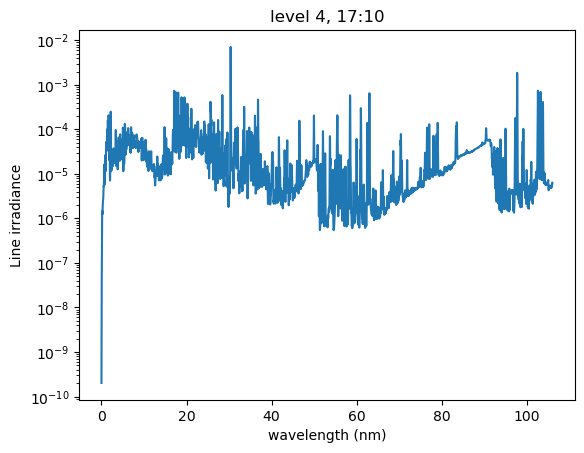

17 : 12


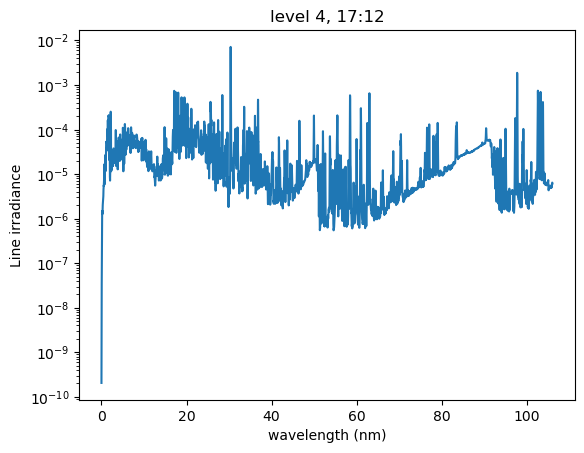

17 : 14


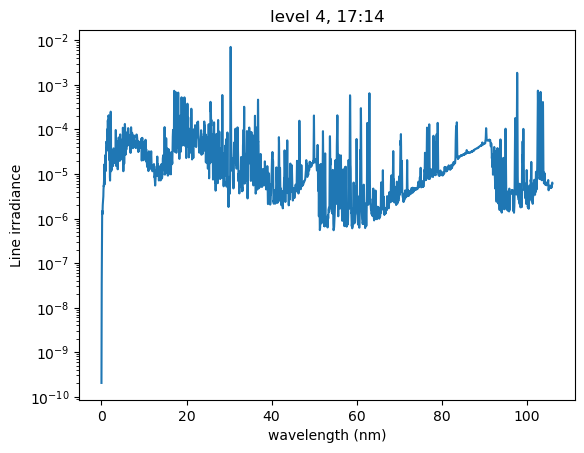

17 : 16


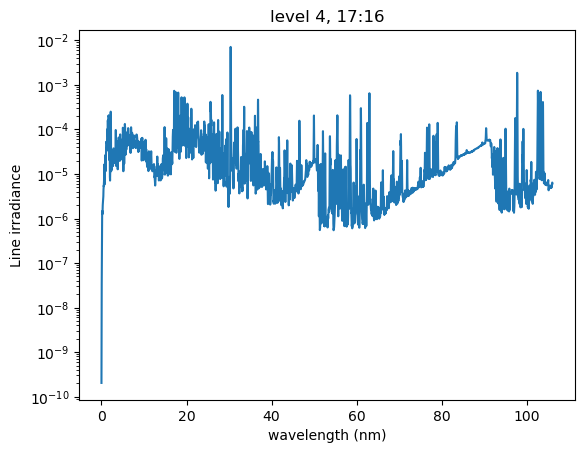

17 : 18


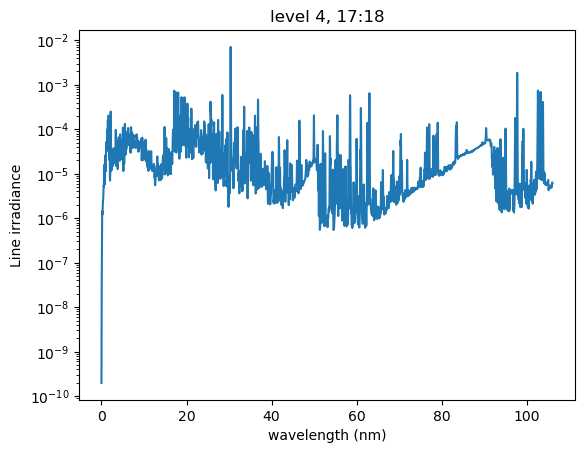

17 : 20


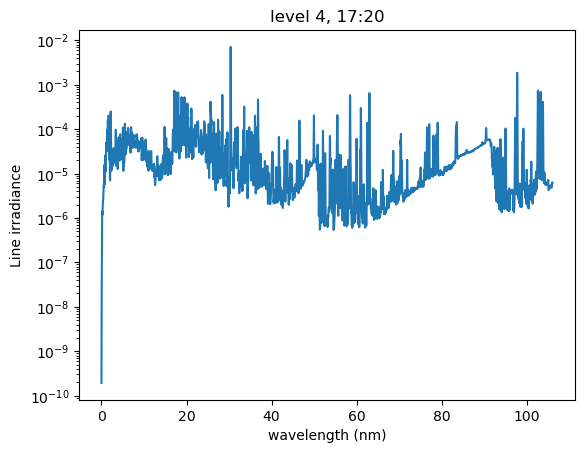

17 : 22


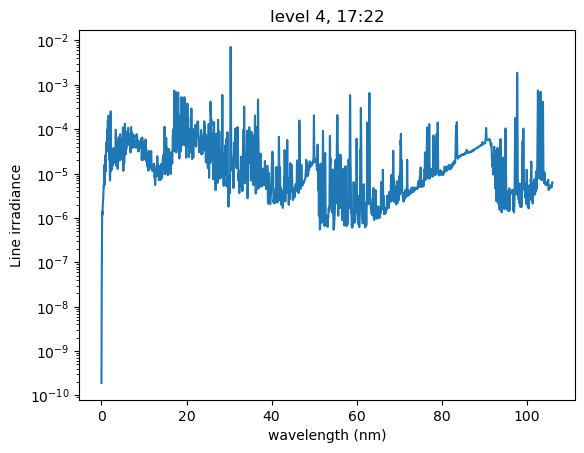

17 : 24


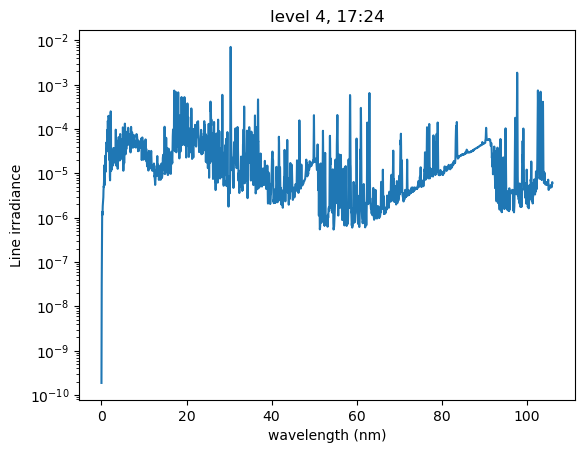

17 : 26


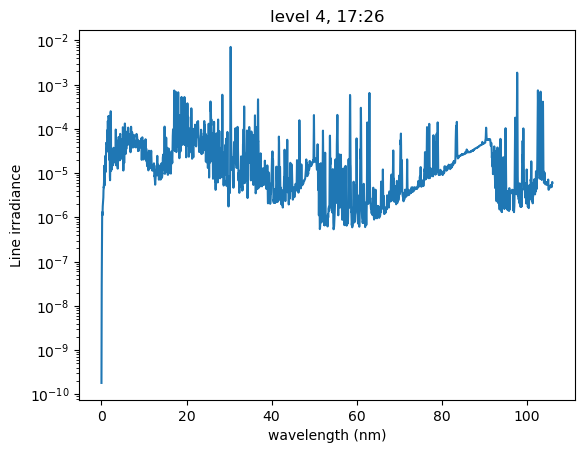

17 : 28


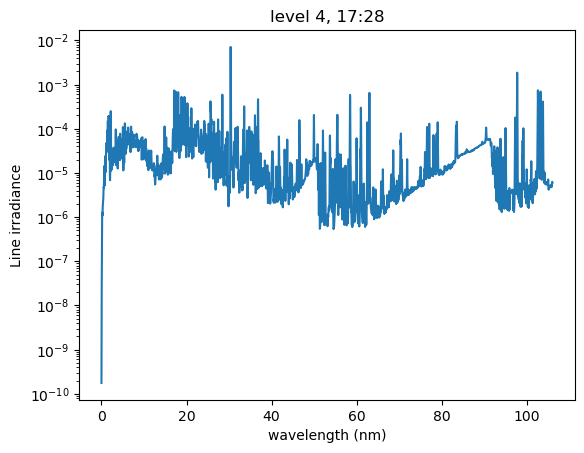

17 : 30


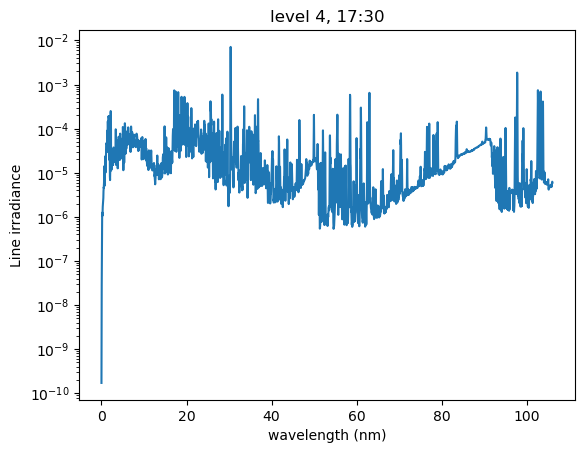

17 : 32


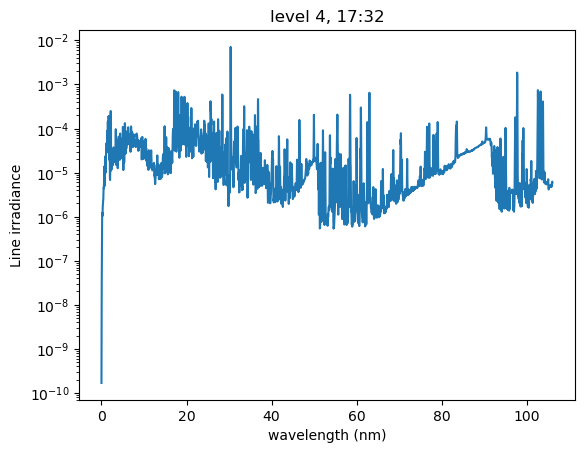

17 : 34


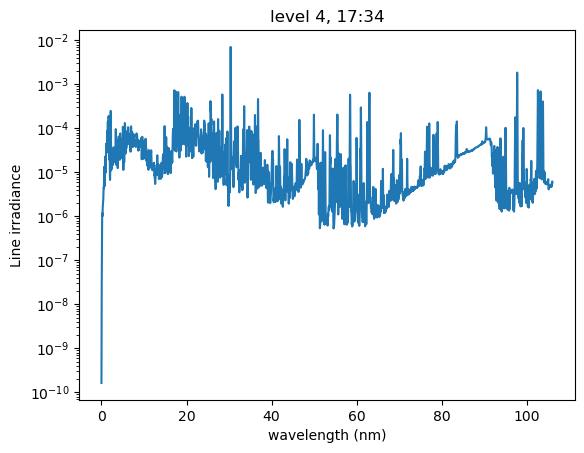

17 : 36


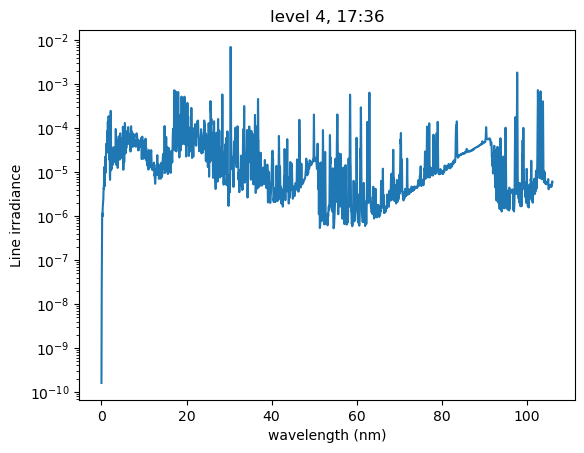

17 : 38


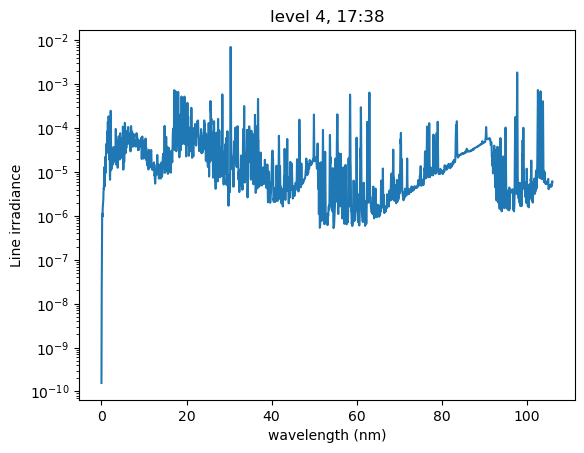

In [79]:
filename = "EVE_L4_0_2012165_00.fit"

with fits.open(filename) as hdul:
    

    hdu = hdul["Spectrum"]
    print(f"\n{"Spectrum"}")
    print(hdu.columns.names)
    print(np.shape(hdu.data[0]["SOD"]))
    print(np.shape(hdu.data[0]["WAVELENGTH"]))
    print(np.shape(hdu.data[0]["SPECTRA"]))

    
    for i in range (1030,1060,2):
        time=i
        print((i//60),":",(i%60))
        plt.xlabel("wavelength (nm)")
        plt.ylabel("Line irradiance")
        plt.title(f"level 4, {(i//60)}:{(i%60)}")
        plt.yscale('log')
        #plt.xlim(93,94)
        #plt.ylim(1e-7,0.8e-4)
        plt.plot(hdu.data[0]["WAVELENGTH"],hdu.data[0]["SPECTRA"][:,time])
        plt.show()

(5300,)
105.99
0.03


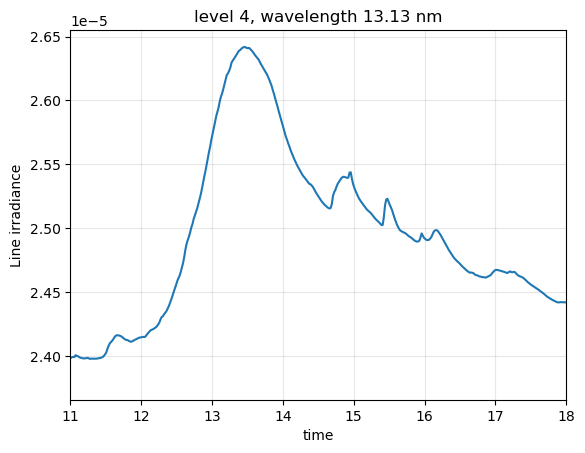

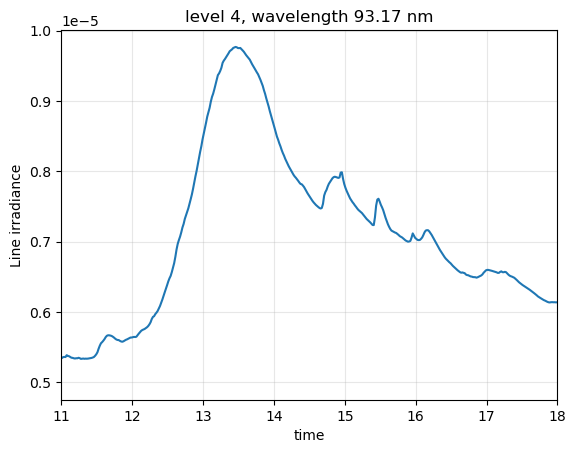

In [105]:
filename = "EVE_L4_0_2012165_00.fit"

with fits.open(filename) as hdul:
    

    hdu = hdul["Spectrum"]
    #print(f"\n{"Spectrum"}")
    #print(hdu.columns.names)
    #print(np.shape(hdu.data[0]["SOD"]))
    print(np.shape(hdu.data[0]["WAVELENGTH"]))
    print(hdu.data[0]["WAVELENGTH"][-1])
    print(hdu.data[0]["WAVELENGTH"][1])
    #print(np.shape(hdu.data[0]["SPECTRA"]))

    
    

    for wave_index in [656, 4658]:
        plt.xlabel("time")
        plt.ylabel("Line irradiance")
        plt.title(f"level 4, wavelength {hdu.data[0]["WAVELENGTH"][wave_index]} nm")
        #plt.yscale('log')
        plt.xlim(11,18)
        #plt.ylim(1e-7,0.8e-4)
        plt.plot((hdu.data[0]["SOD"])/3600,hdu.data[0]["SPECTRA"][wave_index])
        plt.grid(True, alpha=0.3)
        plt.show()

In [76]:
result = Fido.search(a.Time('2012/06/13 07:23:56', '2012/06/13 07:23:57'), a.Instrument("EVE"),  a.Level(4))
Fido.fetch(result)

Files Downloaded:   0%|                                                                        | 0/2 [00:00<?, ?file/s]
EVE_L4_0_2012165_00:   0%|                                                                 | 0.00/30.6M [00:00<?, ?B/s]
EVE_L4_0_2012165_00:   0%|                                                      | 1.02k/30.6M [00:00<1:22:15, 6.20kB/s]

EVE_L4_LINESFIT_2012165_00:   0%|                                                          | 0.00/12.8M [00:00<?, ?B/s]
EVE_L4_0_2012165_00:   0%|                                                        | 23.1k/30.6M [00:00<05:24, 94.1kB/s]
EVE_L4_0_2012165_00:   0%|                                                         | 53.3k/30.6M [00:00<03:35, 142kB/s]

EVE_L4_LINESFIT_2012165_00:   0%|                                                 | 1.02k/12.8M [00:00<46:42, 4.57kB/s]
EVE_L4_0_2012165_00:   0%|▏                                                        | 90.2k/30.6M [00:00<02:26, 208kB/s]

EVE_L4_LINESFIT_2012165_00:   0%|▏   

['/Users/scottd/sunpy/data/EVE_L4_0_2012165_00', '/Users/scottd/sunpy/data/EVE_L4_LINESFIT_2012165_00']

In [ ]:
testing=1
plotting=1




if 1==1:


    
    #for k in arr:

        
        file = "EVE_L4_0_2012165_00.fit"
        
        with fits.open(file) as hdul:

            
             hdu = hdul["Spectrum"]
             

    
             for i in range (1030,1060,2):
                time=i
                print((i//60),":",(i%60))
                plt.xlabel("wavelength (nm)")
                plt.ylabel("Line irradiance")
                plt.title(f"level 4, {(i//60)}:{(i%60)}")
                plt.yscale('log')
                #plt.xlim(93,94)
                #plt.ylim(1e-7,0.8e-4)
                plt.plot(hdu.data[0]["WAVELENGTH"],hdu.data[0]["SPECTRA"][:,time])
                plt.show()
        
        
        # Convert YYYYDOY and SOD to datetime
        times = []
        for yd, seconds in zip(year_doy, sod):
            year = int(yd) // 1000
            doy = int(yd) % 1000
            dt = datetime(year, 1, 1) + timedelta(
                days=doy - 1, seconds=float(seconds)
            )
            times.append(dt)
    
        
        start = time_add(peak_time[k],-25)
        end = time_add(peak_time[k],30)
            
        mask = [(datetime.strptime(start, "%Y-%m-%d %H:%M:%S.%f") <= t <= datetime.strptime(end, "%Y-%m-%d %H:%M:%S.%f")) for t in times]
            
        filtered_times = [t for t, m in zip(times, mask) if m]
        
            
        print(len(times))
                        
        ######################################################## getting the peak flare flux at event peak time 
        print('--'*100); print('--'*100); print('--'*100); print('--'*100); print('--'*100); print('--'*100)
        print(flare_class[k])
        print(radius[k], 'degrees')
         
    
        goes = ts.TimeSeries(xrayfilename[k])
        goes_flare = goes.truncate(start, end)
        # GOES long-wavelength channel: 1–8 Å
        flux = goes_flare.to_dataframe()["xrsb"]
        # Find peak flux and its time
        peak_flux = flux.max()
        soft_xray=peak_flux
        print(f"Peak flux: {peak_flux:.4e} W/m²")
        background_softxray=flux.min()


        # goes graph
        if plotting==1:
            
            df = goes_flare.to_dataframe()
            fig, ax = plt.subplots(figsize=(12, 5))
            ax.plot(df.index, df["xrsb"], color="red", label="GOES 1–8 Å flux")
            #ax.axvline(peak_time[k], color="blue", linestyle="--", label="Event time")
            ax.set_xlabel("Time (UTC)")
            ax.set_ylabel("X-ray flux (W/m²)")
            ax.set_yscale("log")
            plt.show()
        
        emisflx=[] 
        bckgrdflx=[]
        
        for i in range(71):          # max is 71
            # Choose an emission line
            line_index = i

            filtered_values = [v for v, m in zip(line_irradiance[:, line_index], mask) if m]
            
            #print({meta[line_index]['NAME']})
            
            if (int(np.average(filtered_values))<0): #get rid of dead data time sections 
                emisflx.append('Nan')
                bckgrdflx.append('Nan')
                continue
            if (int(np.min(filtered_values))<0): #get rid of data time sections with a secton of it not working 
                emisflx.append('Nan')
                bckgrdflx.append('Nan')
                continue
            
            
            
            emisflx.append(max(filtered_values))     #need to truncate too
            bckgrdflx.append(min(filtered_values))
            
            
            if plotting==1:
                plt.figure(figsize=(10, 5))
                plt.plot(filtered_times, filtered_values)
                plt.xlabel("Time (UTC; verify time convention)")
                #plt.xlim(start, end)
                plt.ylabel("Line irradiance")
                plt.title(
                    f"EVE Level 2: {meta[line_index]['NAME']} "
                    f"({meta[line_index]['WAVE_CENTER']} Å)"
                    f", Start: {times[0]}"
                )
                
                plt.axvline(peak_time[k],color="red")      
                plt.axvline(start,color="green")

                
                plt.gca().xaxis.set_major_formatter(
                    mdates.DateFormatter("%H:%M")
                )
                plt.grid(True, alpha=0.3)
                plt.tight_layout()
                plt.show()